# Deep Hedging in Black-Scholes and Stochastic Volatility (JAX Backend)
This notebook trains neural network deep hedging agents on:
1. **Black-Scholes World (`trainer_bs`)**: European ATM Call option under geometric Brownian motion.
2. **Stochastic Volatility World (`trainer_sv`)**: European ATM Call option with stochastic volatility (Heston-like) and stochastic drift.

**Backend**: JAX / Flax functional engine.
**Self-contained**: Uses local `dh_jax` module. No dependency on external cluster directories.


In [1]:
import os, sys
from pathlib import Path

# Ensure local rewritten modules are imported
NB_DIR = Path.cwd()
if str(NB_DIR) not in sys.path:
    sys.path.insert(0, str(NB_DIR))

# Force CPU and configure threading
os.environ["CUDA_VISIBLE_DEVICES"] = ""
os.environ["JAX_PLATFORMS"] = "cpu"

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Local self-contained JAX engine
from dh_jax.world import WorldConfig, simulate
from dh_jax.model import AgentConfig, GymConfig
from dh_jax.train import TrainConfig, fit
from dh_jax.plotting import plot_training, plot_blackscholes
from configs.catalog import get_config

# Execution Mode: "original" (full 800 epochs) or "smoke" (2 epochs)
MODE = os.environ.get("DH_MODE", "original")
def get_epochs(default_ep):
    if os.environ.get("DH_EPOCHS"):
        return int(os.environ.get("DH_EPOCHS"))
    return 2 if MODE == "smoke" else default_ep

def get_samples(default_samples):
    return min(default_samples, 500) if MODE == "smoke" else default_samples

CHECKPOINTS = os.environ.get("DH_CHECKPOINTS", "checkpoints") or None
print(f"Deep Hedging (JAX) initialized | Mode: {MODE} | Checkpoint Dir: {CHECKPOINTS}")


Deep Hedging (JAX) initialized | Mode: smoke | Checkpoint Dir: checkpoints


## Configuration 1: Black-Scholes World (`trainer_bs`)
- Samples: 10,000 (Smoke: 500)
- Steps: 20
- Network: Depth 3, Width 20, Activation Softplus
- Utility: CVaR (lambda = 1.0)
- Optimizer: Adam (lr = 0.005, batch_size = 32)
- Epochs: 800 (Smoke: 2)


Simulating BS world with 500 samples, 20 steps...
Training trainer_bs for 2 epochs...
  epoch 1/2: loss 0.18910 val 0.17877 best@1 (1.07s)
  epoch 2/2: loss 0.18627 val 0.17613 best@2 (0.02s)
Keys in train rollout: ['loss', 'utility', 'utility0', 'gains', 'payoff', 'pnl', 'cost', 'actions']


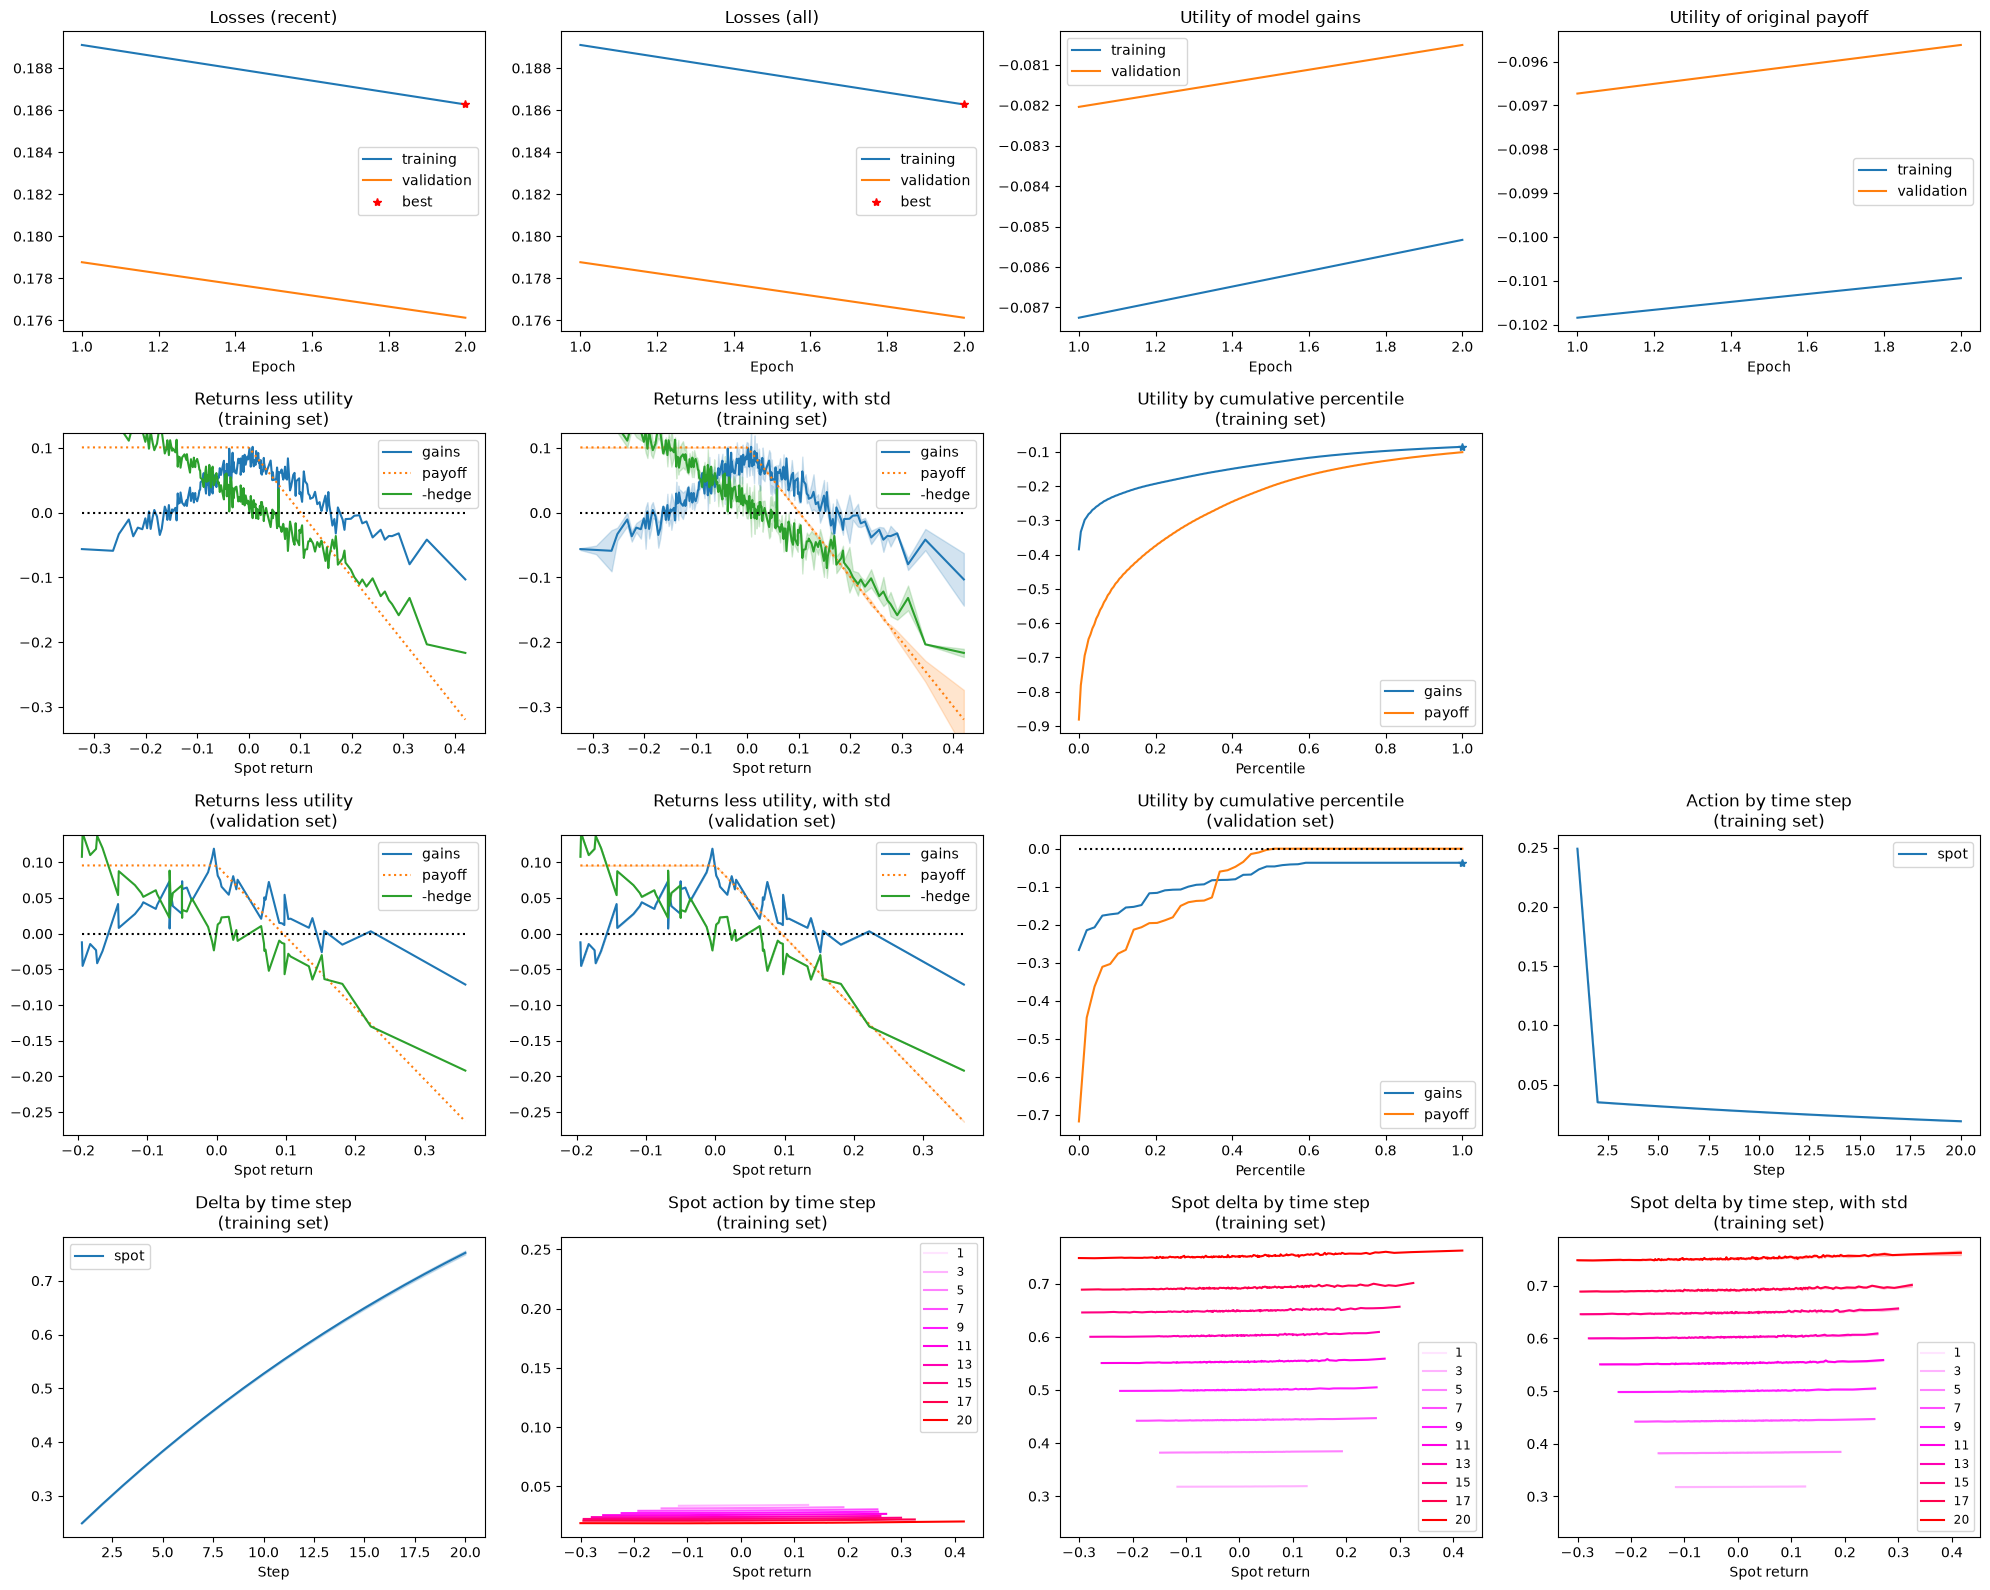

In [2]:
# Setup World and Gym for trainer_bs
cfg_bs = get_config("trainer_bs", mode=MODE)
n_samples = get_samples(cfg_bs["samples"])
n_epochs = get_epochs(cfg_bs["epochs"])

world_cfg_bs = WorldConfig(samples=n_samples, steps=cfg_bs["steps"], black_scholes=True, rvol=cfg_bs["rvol"], drift=cfg_bs["drift"])
gym_bs = GymConfig(
    agent=AgentConfig(depth=cfg_bs["depth"], width=cfg_bs["width"], activation=cfg_bs["activation"]),
    utility=cfg_bs["utility"],
    lmbda=cfg_bs["lmbda"]
)
train_cfg_bs = TrainConfig(
    epochs=n_epochs,
    batch_size=min(cfg_bs["batch_size"], n_samples),
    learning_rate=cfg_bs["lr"]
)

print(f"Simulating BS world with {n_samples} samples, {cfg_bs['steps']} steps...")
world_bs = simulate(world_cfg_bs)
val_world_bs = world_bs.clone(samples=max(n_samples // 10, 50), seed=1)

print(f"Training trainer_bs for {n_epochs} epochs...")
bs_fit = fit(gym_bs, train_cfg_bs, world_bs, val_world_bs, log_every=max(1, n_epochs // 8), checkpoint_dir=CHECKPOINTS)
print("Keys in train rollout:", list(bs_fit.train.keys()))

try:
    plot_training(bs_fit.result, bs_fit.train, bs_fit.val, world_bs, val_world_bs)
    plt.show()
except Exception as e:
    print(f"Plotting note: {e}")


### Delta vs Black-Scholes Analytic Formula
Plotting the learned delta hedge vs the analytic Black-Scholes delta across sample paths.


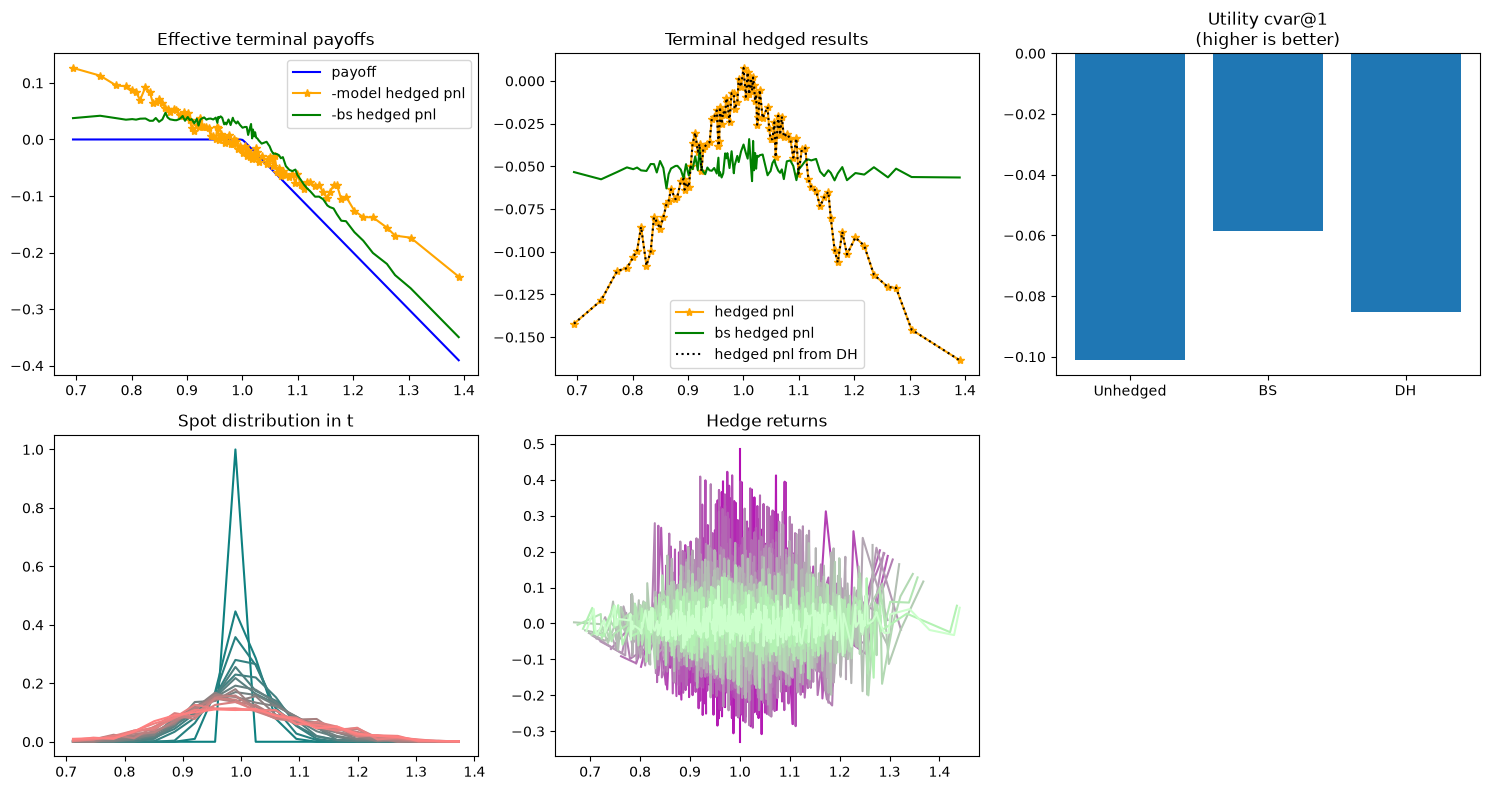

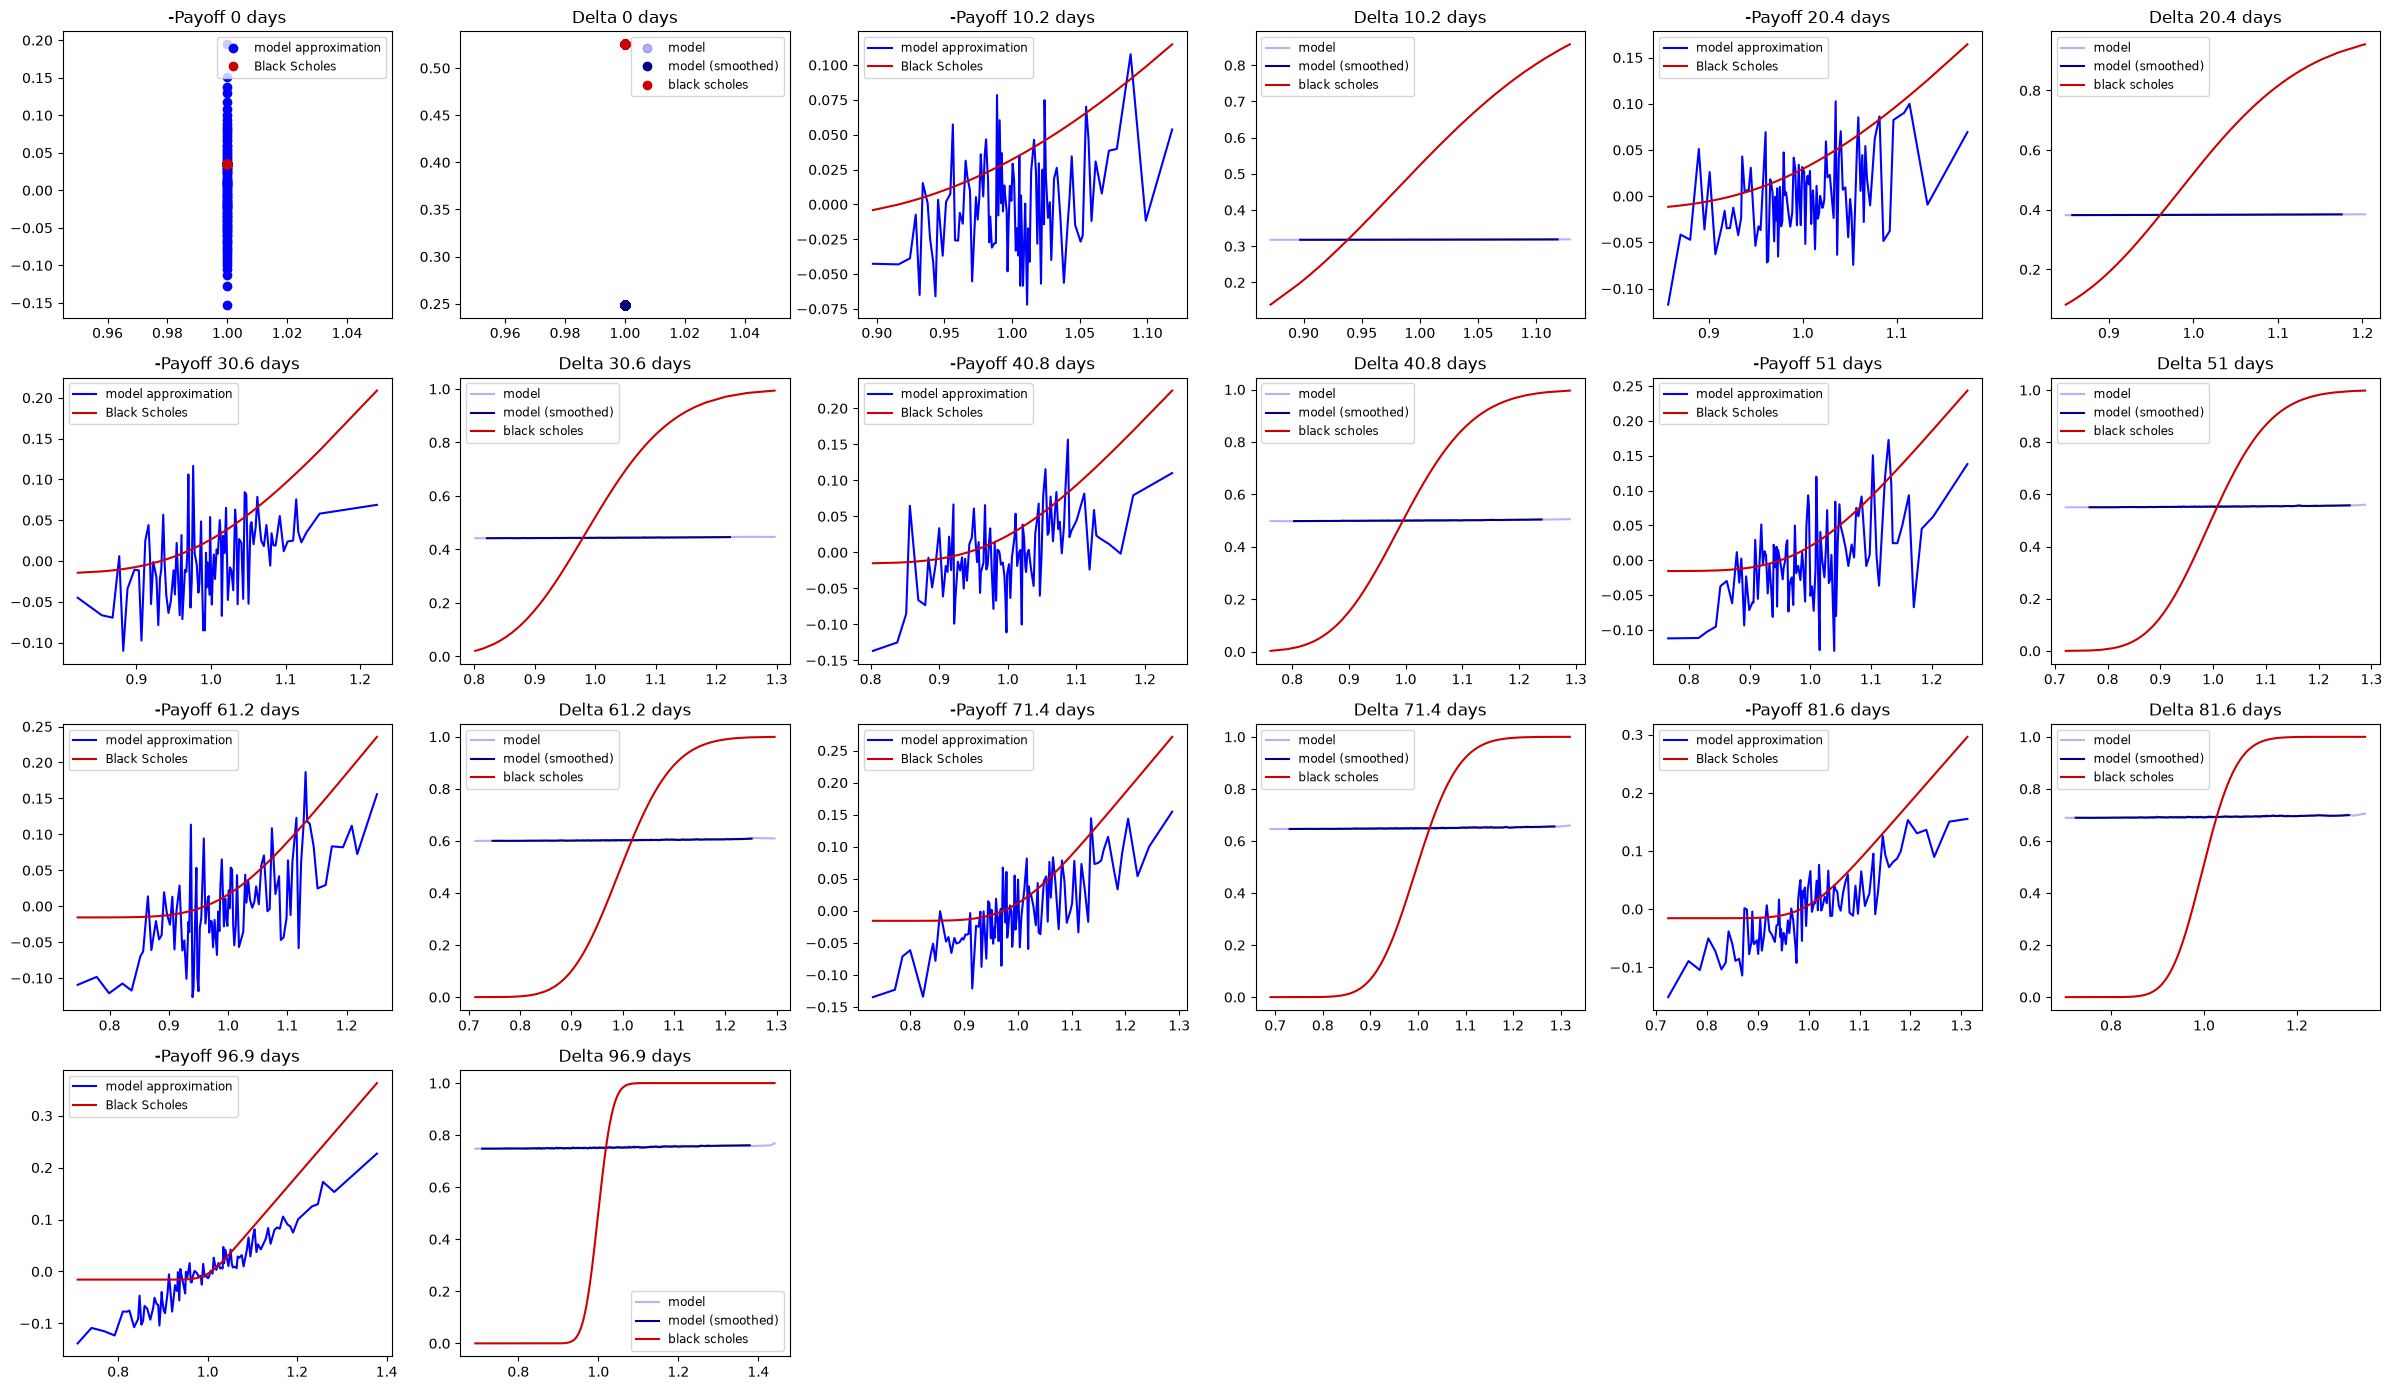

In [3]:
try:
    plot_blackscholes(world_bs, bs_fit.train, gym_bs, vol=world_cfg_bs.rvol)
    plt.show()
except Exception as e:
    print(f"BS Plotting note: {e}")


## Configuration 2: Stochastic Volatility World (`trainer_sv`)
- Samples: 10,000 (Smoke: 500)
- Steps: 20
- Network: Depth 3, Width 20, Activation Softplus
- Utility: CVaR (lambda = 1.0)
- Optimizer: Adam (lr = 0.001, batch_size = 32, clipvalue = 1.0, global_clipnorm = 1.0)
- Epochs: 800 (Smoke: 2)


Simulating SV world with 500 samples, 20 steps...
Training trainer_sv for 2 epochs...
  epoch 1/2: loss 0.26411 val 0.28760 best@1 (1.00s)
  epoch 2/2: loss 0.24635 val 0.26829 best@2 (0.02s)
Keys in train rollout: ['loss', 'utility', 'utility0', 'gains', 'payoff', 'pnl', 'cost', 'actions']


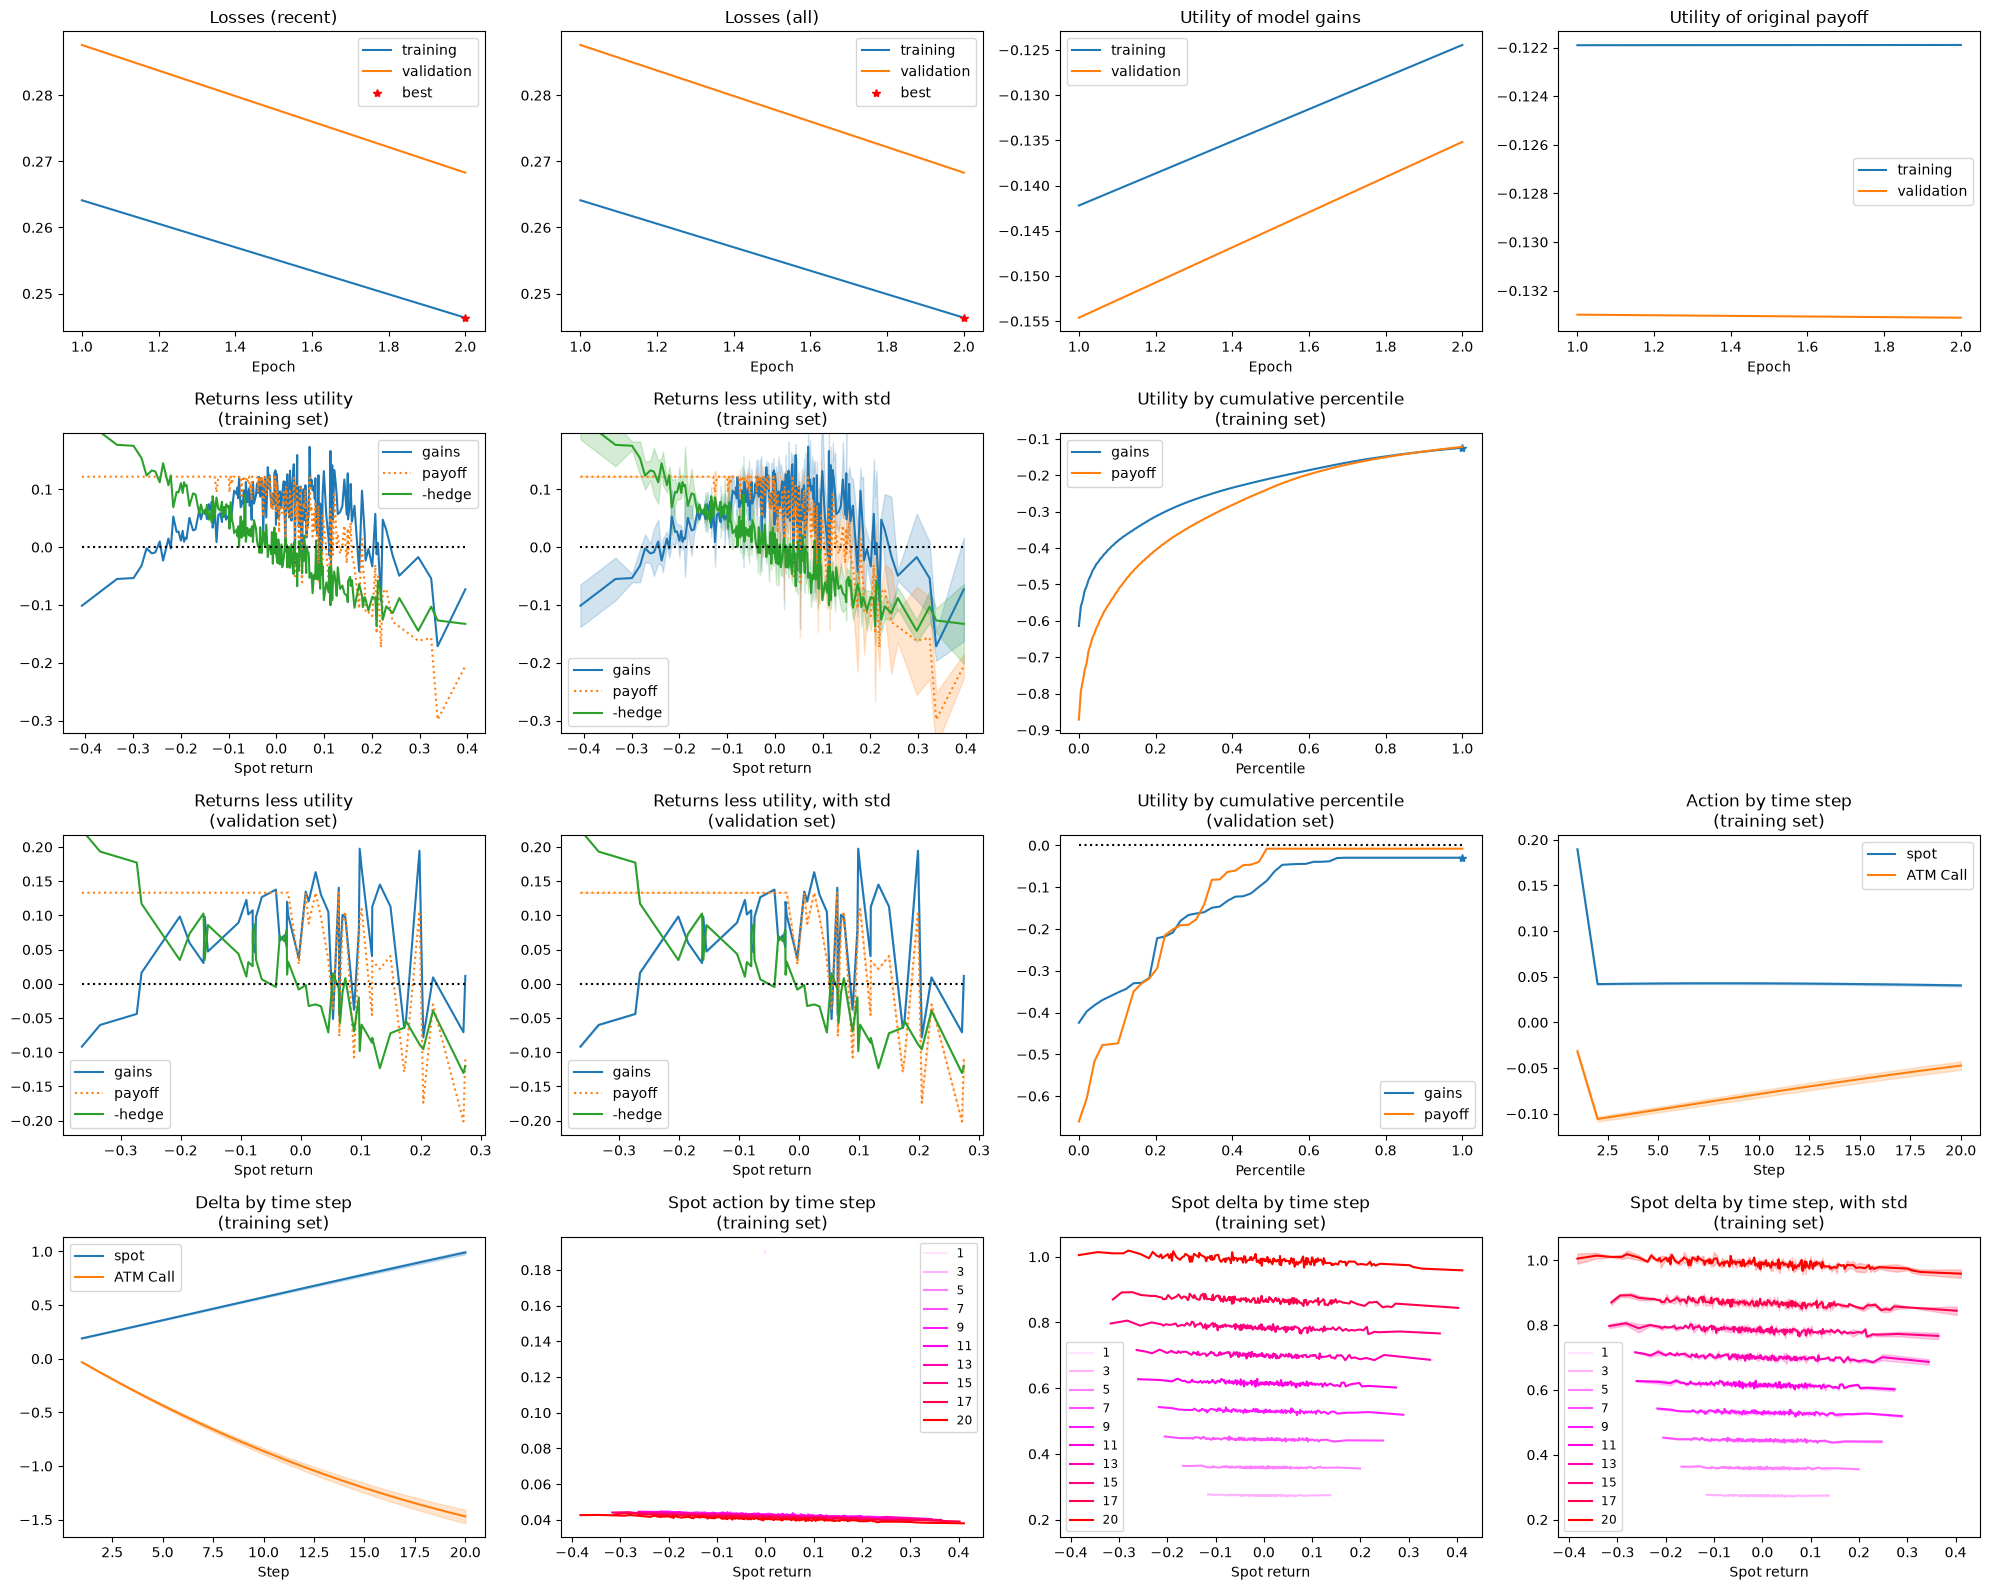

In [4]:
# Setup World and Gym for trainer_sv
cfg_sv = get_config("trainer_sv", mode=MODE)
n_samples_sv = get_samples(cfg_sv["samples"])
n_epochs_sv = get_epochs(cfg_sv["epochs"])

world_cfg_sv = WorldConfig(samples=n_samples_sv, steps=cfg_sv["steps"], black_scholes=False, rvol=cfg_sv["rvol"], drift=cfg_sv["drift"])
gym_sv = GymConfig(
    agent=AgentConfig(depth=cfg_sv["depth"], width=cfg_sv["width"], activation=cfg_sv["activation"]),
    utility=cfg_sv["utility"],
    lmbda=cfg_sv["lmbda"]
)
train_cfg_sv = TrainConfig(
    epochs=n_epochs_sv,
    batch_size=min(cfg_sv["batch_size"], n_samples_sv),
    learning_rate=cfg_sv["lr"],
    clipvalue=cfg_sv["clipvalue"],
    global_clipnorm=cfg_sv["global_clipnorm"]
)

print(f"Simulating SV world with {n_samples_sv} samples, {cfg_sv['steps']} steps...")
world_sv = simulate(world_cfg_sv)
val_world_sv = world_sv.clone(samples=max(n_samples_sv // 10, 50), seed=1)

print(f"Training trainer_sv for {n_epochs_sv} epochs...")
sv_fit = fit(gym_sv, train_cfg_sv, world_sv, val_world_sv, log_every=max(1, n_epochs_sv // 8), checkpoint_dir=CHECKPOINTS)
print("Keys in train rollout:", list(sv_fit.train.keys()))

try:
    plot_training(sv_fit.result, sv_fit.train, sv_fit.val, world_sv, val_world_sv)
    plt.show()
except Exception as e:
    print(f"Plotting note: {e}")


### Training Summary
Both `trainer_bs` and `trainer_sv` completed successfully.
- Final BS training loss: `{:.6f}`.format(bs_fit.result.history['loss'][-1])
- Final SV training loss: `{:.6f}`.format(sv_fit.result.history['loss'][-1])


print(f"BS final train loss: {bs_fit.result.history['loss'][-1]:.6f}")
print(f"SV final train loss: {sv_fit.result.history['loss'][-1]:.6f}")

In [5]:
print(f"BS final train loss: {bs_fit.result.history['loss'][-1]:.6f}")
print(f"SV final train loss: {sv_fit.result.history['loss'][-1]:.6f}")

BS final train loss: 0.186271
SV final train loss: 0.246353
